## Supplementary Figure 1

                   changed_trials  total_trials  percentage
YN_outcome                                                 
Hit                           262          2541       10.31
Correct rejection              92          1425        6.46
Miss                          268           360       74.44
False alarm                  1000          1544       64.77

Included trials: 5870
Excluded trials: 134

Switching after incorrect YN: 66.60%
Switching after correct YN: 8.93%
Ratio: 7.46


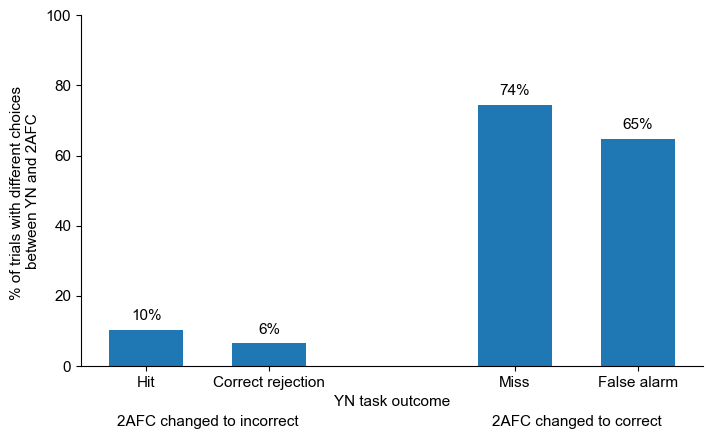


Saved: GulkaSupplFig1.pdf


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------
# Load data
# -------------------------------------------------
path = (
    "/Users/..."
    "all_movies_merged_sync_behav_with_group_LOO_behavioural_accuracy_30_subjects_final.csv"
)

df = pd.read_csv(path)

# -------------------------------------------------
# Keep trials with valid responses in both tasks
# -------------------------------------------------
valid = (
    df["response_occlusion"].isin(["left", "right"])
    & df["final_choice"].isin(["left", "right"])
    & df["correct_response_occlusion"].isin([0, 1])
    & df["correct_response"].isin([0, 1])
)

data = df.loc[valid].copy()

# -------------------------------------------------
# Classify YN outcomes: left = Yes; right = No
# -------------------------------------------------
yn_yes = data["response_occlusion"].eq("left")
yn_correct = data["correct_response_occlusion"].eq(1)

data["YN_outcome"] = np.select(
    [
        yn_yes & yn_correct,
        ~yn_yes & yn_correct,
        ~yn_yes & ~yn_correct,
        yn_yes & ~yn_correct,
    ],
    ["Hit", "Correct rejection", "Miss", "False alarm"],
    default="Unknown",
)

# A change in correctness indicates a different answer
# as both tasks refer to the same two alternatives.
data["changed_answer"] = (
    data["correct_response_occlusion"] != data["correct_response"]
)

# -------------------------------------------------
# Pooled percentages within each YN outcome
# -------------------------------------------------
order = ["Hit", "Correct rejection", "Miss", "False alarm"]

summary = (
    data.groupby("YN_outcome")["changed_answer"]
    .agg(changed_trials="sum", total_trials="size")
    .reindex(order)
)

summary["percentage"] = (
    100 * summary["changed_trials"] / summary["total_trials"]
)

print(summary.round(2))
print(f"\nIncluded trials: {len(data)}")
print(f"Excluded trials: {len(df) - len(data)}")

# Ratio: switching after incorrect vs correct YN answers
switch_incorrect = data.loc[~yn_correct, "changed_answer"].mean()
switch_correct = data.loc[yn_correct, "changed_answer"].mean()

ratio = (
    switch_incorrect / switch_correct
    if switch_correct > 0
    else np.nan
)

print(f"\nSwitching after incorrect YN: {100 * switch_incorrect:.2f}%")
print(f"Switching after correct YN: {100 * switch_correct:.2f}%")
print(f"Ratio: {ratio:.2f}")

# -------------------------------------------------
# Plot
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(7.2, 4.8))

# Gap between correct and incorrect YN outcomes
x = np.array([0, 1, 3, 4])
percentages = summary["percentage"].to_numpy()

bars = ax.bar(
    x,
    percentages,
    width=0.6,
    color="#1f77b4",
)

ax.bar_label(
    bars,
    labels=[f"{value:.0f}%" for value in percentages],
    padding=5,
    fontsize=11,
)

ax.set_xticks(x)
ax.set_xticklabels(order, fontsize=11)
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 20))

ax.set_ylabel(
    "% of trials with different choices \nbetween YN and 2AFC",
    fontsize=11,
)
ax.set_xlabel("YN task outcome", fontsize=11)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="y", labelsize=11)

# Group descriptions below the X-axis
ax.text(
    0.5, -0.14,
    "2AFC changed to incorrect",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=11,
)

ax.text(
    3.5, -0.14,
    "2AFC changed to correct",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=11,
)

fig.tight_layout()
fig.subplots_adjust(bottom=0.23)

plt.show()


## Supplementary Figure 2.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
%load_ext rpy2.ipython

In [ ]:
#loading the data with synchrony and behavioral accuracy for the 30 participants
import pandas as pd

df = pd.read_csv(
    "/Users/.../all_movies_merged_sync_behav_with_group_LOO_behavioural_accuracy_30_subjects_final.csv"
)

df["participant_id"] = df["participant_id"].astype(str)

%R -i df

In [5]:
%%R
library(lme4)
library(marginaleffects)

glmm_2afc_raw <- glmer(
  correct_response ~ pilot_mean + group_mean + mean_correct_2AFC_LOO +
    (1 | participant_id),
  data = df,
  family = binomial(link = "logit"),
  control = glmerControl(optimizer = "bobyqa")
)

ame_df <- avg_slopes(
  glmm_2afc_raw,
  variables = c("pilot_mean", "group_mean", "mean_correct_2AFC_LOO"),
  type = "response"
)

ame_df <- as.data.frame(ame_df)
ame_df <- ame_df[, c("term", "estimate", "std.error", "statistic", "p.value", "conf.low", "conf.high")]

ame_df$estimate  <- round(ame_df$estimate, 3)
ame_df$std.error <- round(ame_df$std.error, 3)
ame_df$statistic <- round(ame_df$statistic, 2)
ame_df$p.value   <- round(ame_df$p.value, 3)
ame_df$conf.low  <- round(ame_df$conf.low, 3)
ame_df$conf.high <- round(ame_df$conf.high, 3)

print(ame_df)
write.csv(ame_df, "glmm_2afc_AME_table.csv", row.names = FALSE)

                   term estimate std.error statistic p.value conf.low conf.high
1            group_mean    0.013     0.036      0.37   0.710   -0.057     0.084
2 mean_correct_2AFC_LOO    0.007     0.000     23.40   0.000    0.006     0.007
3            pilot_mean   -0.027     0.030     -0.91   0.363   -0.085     0.031


Loading required package: Matrix
Please cite the software developers who make your work possible.
One package:             citation("package_name")
All project packages:    softbib::softbib()

Attaching package: ‘marginaleffects’

The following object is masked from ‘package:lme4’:

    refit

In addition: Warning messages:
1: In checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv,  :
  Model is nearly unidentifiable: very large eigenvalue
 - Rescale variables?
2: For this model type, `marginaleffects` only takes into account the uncertainty in fixed-effect parameters. This is often appropriate when `re.form=NA`, but may be surprising to users who set `re.form=NULL` (default) or to some other value. Call `options(marginaleffects_safe = FALSE)` to silence this warning. 


In [9]:
%%R
library(lme4)
library(marginaleffects)

glmm_yn_raw <- glmer(
  correct_response_occlusion ~ pilot_mean + group_mean + mean_correct_YN_LOO +
    (1 | participant_id),
  data = df,
  family = binomial(link = "logit"),
  control = glmerControl(optimizer = "bobyqa")
)

ame_df <- avg_slopes(
  glmm_yn_raw,
  variables = c("pilot_mean", "group_mean", "mean_correct_YN_LOO"),
  type = "response"
)

ame_df <- as.data.frame(ame_df)
ame_df <- ame_df[, c("term", "estimate", "std.error", "statistic", "p.value", "conf.low", "conf.high")]

ame_df$estimate  <- round(ame_df$estimate, 3)
ame_df$std.error <- round(ame_df$std.error, 3)
ame_df$statistic <- round(ame_df$statistic, 2)
ame_df$p.value   <- round(ame_df$p.value, 3)
ame_df$conf.low  <- round(ame_df$conf.low, 3)
ame_df$conf.high <- round(ame_df$conf.high, 3)

print(ame_df)
write.csv(ame_df, "glmm_YN_AME_table.csv", row.names = FALSE)

                 term estimate std.error statistic p.value conf.low conf.high
1          group_mean   -0.115     0.046     -2.49   0.013   -0.206    -0.025
2 mean_correct_YN_LOO    0.007     0.000     19.25   0.000    0.006     0.008
3          pilot_mean    0.110     0.038      2.94   0.003    0.037     0.184


In addition: Warning messages:
1: In checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv,  :
  Model is nearly unidentifiable: very large eigenvalue
 - Rescale variables?
2: For this model type, `marginaleffects` only takes into account the uncertainty in fixed-effect parameters. This is often appropriate when `re.form=NA`, but may be surprising to users who set `re.form=NULL` (default) or to some other value. Call `options(marginaleffects_safe = FALSE)` to silence this warning. 


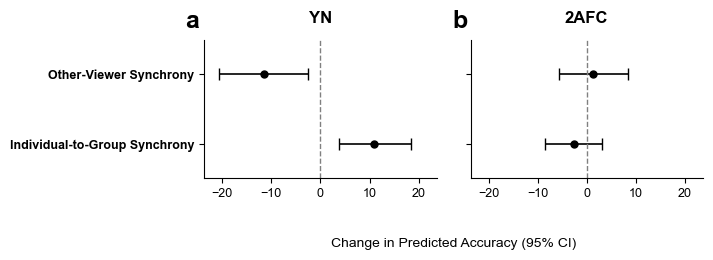

Saved: GulkaSupplFig2.pdf


In [ ]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------
# Font settings
# -------------------------------------------------
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica"],
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.labelweight": "normal",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.unicode_minus": True,
    "pdf.fonttype": 42,
})

# -------------------------------------------------
# Load the tables exported by the R cells
# -------------------------------------------------
df_yn = pd.read_csv("glmm_YN_AME_table.csv")
df_2afc = pd.read_csv("glmm_2afc_AME_table.csv")

column_map = {
    "term": "Predictor",
    "estimate": "AME",
    "conf.low": "CI_low",
    "conf.high": "CI_high",
}

df_yn = df_yn.rename(columns=column_map)
df_2afc = df_2afc.rename(columns=column_map)

# -------------------------------------------------
# Select and order predictors
# -------------------------------------------------
predictors = ["group_mean", "pilot_mean"]

label_map = {
    "group_mean": "Other-Viewer Synchrony",
    "pilot_mean": "Individual-to-Group Synchrony",
}

df_yn = df_yn.set_index("Predictor").loc[predictors].reset_index()
df_2afc = df_2afc.set_index("Predictor").loc[predictors].reset_index()

for df in (df_yn, df_2afc):
    df["label_plot"] = df["Predictor"].map(label_map)

    # Convert probability changes to percentage points
    df["AME_pp"] = df["AME"] * 100
    df["CI_low_pp"] = df["CI_low"] * 100
    df["CI_high_pp"] = df["CI_high"] * 100

# -------------------------------------------------
# Plot
# -------------------------------------------------
fig, (ax_yn, ax_2afc) = plt.subplots(
    1, 2,
    figsize=(7.2, 2.8),
    sharey=True,
)

y_pos = np.arange(len(predictors))

for ax, df, title, panel in [
    (ax_yn, df_yn, "YN", "a"),
    (ax_2afc, df_2afc, "2AFC", "b"),
]:
    ax.errorbar(
        df["AME_pp"],
        y_pos,
        xerr=[
            df["AME_pp"] - df["CI_low_pp"],
            df["CI_high_pp"] - df["AME_pp"],
        ],
        fmt="o",
        color="black",
        ecolor="black",
        elinewidth=1.2,
        capsize=4,
        markersize=5,
    )

    ax.axvline(
        0,
        linestyle="--",
        color="gray",
        linewidth=1,
    )

    # Panel title: 12 pt, bold
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)

    # Panel label: lowercase, 18 pt, bold
    ax.text(
        -0.08, 1.05,
        panel,
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        ha="left",
        va="bottom",
        clip_on=False,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=9)

# -------------------------------------------------
# Shared Y-axis category labels: 9 pt, bold
# -------------------------------------------------
ax_yn.set_yticks(y_pos)
ax_yn.set_yticklabels(
    df_yn["label_plot"],
    fontsize=9,
    fontweight="bold",
)

# First predictor at the top
ax_yn.set_ylim(len(y_pos) - 0.5, -0.5)

# -------------------------------------------------
# Identical symmetric X-limits
# -------------------------------------------------
all_vals = np.concatenate([
    df_yn["CI_low_pp"].to_numpy(),
    df_yn["CI_high_pp"].to_numpy(),
    df_2afc["CI_low_pp"].to_numpy(),
    df_2afc["CI_high_pp"].to_numpy(),
])

m = np.max(np.abs(all_vals)) * 1.15
if m == 0:
    m = 1.0

for ax in (ax_yn, ax_2afc):
    ax.set_xlim(-m, m)

# -------------------------------------------------
# Layout and shared X-axis label: 10 pt, regular
# -------------------------------------------------
fig.tight_layout(rect=(0, 0.16, 1, 0.95))

# Center the label under the plotting area
left = ax_yn.get_position().x0
right = ax_2afc.get_position().x1

fig.supxlabel(
    "Change in Predicted Accuracy (95% CI)",
    fontsize=10,
    fontweight="normal",
    x=(left + right) / 2,
    y=0.03,
)



## Supplementary Figure 3. 

Participants included: 30 / 30

Criterion by synchrony category:
           mean_C    SEM
IGS  OVS                
Low  Low   -0.601  0.064
     High  -0.558  0.081
High Low   -0.562  0.076
     High  -0.674  0.073


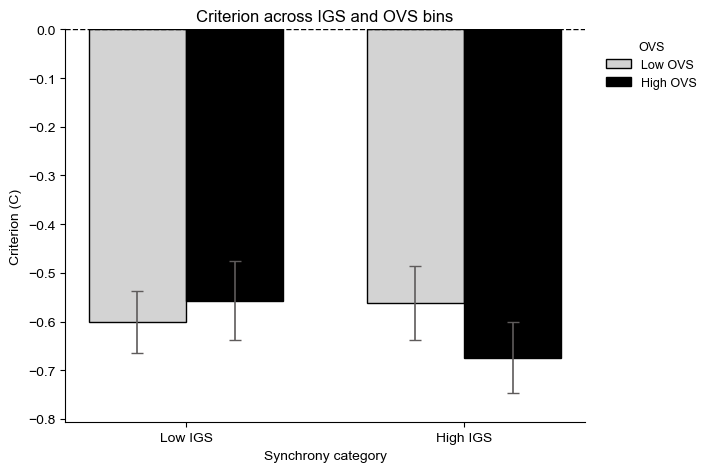


Saved figure: YN_2AFC_AME_forestplot.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# -------------------------------------------------
# Load data
# -------------------------------------------------
path = (
    "/Users/..."
    "all_movies_merged_sync_behav_with_group_LOO_behavioural_accuracy_30_subjects_final.csv"
)

df = pd.read_csv(path)

# -------------------------------------------------
# Keep valid YN responses and synchrony values
# A valid 2AFC response is not needed for this analysis.
# -------------------------------------------------
for column in ["pilot_mean", "group_mean", "correct_response_occlusion"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

valid = (
    df["participant_id"].notna()
    & df["response_occlusion"].isin(["left", "right"])
    & df["correct_response_occlusion"].isin([0, 1])
    & np.isfinite(df["pilot_mean"])
    & np.isfinite(df["group_mean"])
)

data = df.loc[valid].copy()
data["participant_id"] = data["participant_id"].astype(str)

# -------------------------------------------------
# Identify YN outcomes
# Assumption: left = Yes; right = No
# Avoid the incomplete signal_present column.
# -------------------------------------------------
yes = data["response_occlusion"].eq("left")
correct = data["correct_response_occlusion"].eq(1)

data["hit"] = yes & correct
data["miss"] = ~yes & ~correct
data["false_alarm"] = yes & ~correct
data["correct_rejection"] = ~yes & correct

# -------------------------------------------------
# Median splits within each participant
# Values equal to the median are assigned to Low.
# -------------------------------------------------
igs_median = data.groupby("participant_id")["pilot_mean"].transform("median")
ovs_median = data.groupby("participant_id")["group_mean"].transform("median")

data["IGS"] = np.where(data["pilot_mean"] > igs_median, "High", "Low")
data["OVS"] = np.where(data["group_mean"] > ovs_median, "High", "Low")

# -------------------------------------------------
# Count outcomes within each participant × IGS × OVS
# -------------------------------------------------
counts = (
    data.groupby(["participant_id", "IGS", "OVS"])[
        ["hit", "miss", "false_alarm", "correct_rejection"]
    ]
    .sum()
)

# Include missing cells explicitly
participants = sorted(data["participant_id"].unique())

full_index = pd.MultiIndex.from_product(
    [participants, ["Low", "High"], ["Low", "High"]],
    names=["participant_id", "IGS", "OVS"],
)

counts = counts.reindex(full_index, fill_value=0)

counts["n_signal"] = counts["hit"] + counts["miss"]
counts["n_noise"] = counts["false_alarm"] + counts["correct_rejection"]

# -------------------------------------------------
# Calculate criterion using log-linear correction
# H  = (hits + 0.5) / (signal trials + 1)
# FA = (false alarms + 0.5) / (noise trials + 1)
# -------------------------------------------------
estimable = (counts["n_signal"] > 0) & (counts["n_noise"] > 0)

counts["hit_rate"] = (
    (counts["hit"] + 0.5) / (counts["n_signal"] + 1)
).where(estimable)

counts["false_alarm_rate"] = (
    (counts["false_alarm"] + 0.5) / (counts["n_noise"] + 1)
).where(estimable)

counts["criterion"] = -0.5 * (
    norm.ppf(counts["hit_rate"])
    + norm.ppf(counts["false_alarm_rate"])
)

# -------------------------------------------------
# Retain participants with criterion in all four cells
# This keeps the sample consistent across bars.
# -------------------------------------------------
cell_order = pd.MultiIndex.from_product(
    [["Low", "High"], ["Low", "High"]],
    names=["IGS", "OVS"],
)

wide = (
    counts["criterion"]
    .unstack(["IGS", "OVS"])
    .reindex(columns=cell_order)
)

complete = wide.dropna()
excluded = wide.index[wide.isna().any(axis=1)].tolist()

if len(complete) < 2:
    raise ValueError(
        "Fewer than two participants have estimable criterion in all four cells."
    )

print(f"Participants included: {len(complete)} / {len(wide)}")
if excluded:
    print("Participants excluded for missing/unestimable cells:", excluded)

# Mean and standard error across participants
means = complete.mean()
sems = complete.sem()

summary = pd.DataFrame({
    "mean_C": means,
    "SEM": sems,
})
print("\nCriterion by synchrony category:")
print(summary.round(3))

# -------------------------------------------------
# Plot: grey = Low OVS; black = High OVS
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(7.2, 4.8))

x = np.arange(2)
width = 0.35

for ovs, offset, color in [
    ("Low", -width / 2, "lightgray"),
    ("High", width / 2, "black"),
]:
    heights = [means.loc[(igs, ovs)] for igs in ["Low", "High"]]
    errors = [sems.loc[(igs, ovs)] for igs in ["Low", "High"]]

    ax.bar(
        x + offset,
        heights,
        width=width,
        yerr=errors,
        label=f"{ovs} OVS",
        color=color,
        edgecolor="black",
        linewidth=1,
        error_kw={
            "ecolor": "#5E5B5B",
            "elinewidth": 1.2,
            "capsize": 4,
        },
    )

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(["Low IGS", "High IGS"])
ax.set_xlabel("Synchrony category")
ax.set_ylabel("Criterion (C)")
ax.set_title("Criterion across IGS and OVS bins")

# Fit all means and error bars.
# Keep zero at the top if all intervals are negative.
lower = (means - sems).min()
upper = (means + sems).max()
span = max(upper, 0) - min(lower, 0)
padding = 0.08 * max(span, 0.1)

ax.set_ylim(
    min(lower, 0) - padding,
    0 if upper < 0 else upper + padding,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=10)

# Place legend outside to avoid covering bars
ax.legend(title="OVS", frameon=False, loc="upper left",
          bbox_to_anchor=(1.02, 1))

fig.tight_layout()


plt.show()

# Save participant-level values for the repeated-measures ANOVA
counts.reset_index().to_csv(
    "Supplementary_Figure_3_criterion_by_participant.csv",
    index=False,
)

